In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
# Pastikan Drive benar-benar ter-mount (bukan folder lokal biasa)
assert os.path.ismount('/content/drive'), "Drive belum ter-mount! Jalankan ulang sel ini."
print("Drive ter-mount dengan benar.")

Mounted at /content/drive
Drive ter-mount dengan benar.


In [ ]:
!pip install -q roboflow ultralytics

import os, shutil
from roboflow import Roboflow

DRIVE = '/content/drive/MyDrive'
DATASET_DRIVE = f'{DRIVE}/Dataset_Kakao_Version_2'   # permanen
DATASET_LOCAL = '/content/Dataset_Kakao_Version_2'   # salinan kerja (cepat)

if os.path.exists(f'{DATASET_DRIVE}/data.yaml'):
    print("Dataset sudah ada di Drive, download dilewati.")
else:
    from getpass import getpass
    api_key = getpass("CFkAIbomJnHd0Yk5xero")   # jangan tulis key langsung di kode
    rf = Roboflow(api_key=api_key)
    project = rf.workspace("cocoa-thtcu").project("tugas-akhir-kakao")
    version = project.version(2)

    # 1) Download ke disk lokal (stabil dan cepat)
    dataset = version.download("yolov8", location=DATASET_LOCAL)

    # 2) Salin ke Drive agar permanen
    shutil.copytree(DATASET_LOCAL, DATASET_DRIVE, dirs_exist_ok=True)
    print("Dataset berhasil disimpan permanen di:", DATASET_DRIVE)

# Pastikan salinan lokal ada (untuk training)
if not os.path.exists(DATASET_LOCAL):
    shutil.copytree(DATASET_DRIVE, DATASET_LOCAL)

print("Isi dataset di Drive :", os.listdir(DATASET_DRIVE))
print("Isi dataset lokal    :", os.listdir(DATASET_LOCAL))

CFkAIbomJnHd0Yk5xero··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/Dataset_Kakao_Version_2 in yolov8:: 100%|██████████| 5347/5347 [00:00<00:00, 5358.91it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dataset berhasil disimpan permanen di: /content/drive/MyDrive/Dataset_Kakao_Version_2
Isi dataset di Drive : ['valid', 'test', 'README.dataset.txt', 'README.roboflow.txt', 'train', 'data.yaml']
Isi dataset lokal    : ['valid', 'test', 'README.dataset.txt', 'README.roboflow.txt', 'train', 'data.yaml']


In [ ]:
# check NVIDIA
!nvidia-smi

Sun Nov  8 04:21:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os, shutil, glob, yaml, random
from collections import Counter

DRIVE = '/content/drive/MyDrive'

# Permanen (Drive)
DATASET_DRIVE = f'{DRIVE}/Dataset_Kakao_Version_2'
RUNS_DRIVE    = f'{DRIVE}/HASIL_YOLOV8_KAKAO_V2_50EPOCH'
RUN_NAME      = 'kakao_yolov8n_50ep'

# Sementara (disk lokal Colab, cepat)
DATASET_LOCAL = '/content/Dataset_Kakao_Version_2'
YAML_LOCAL    = '/content/data_local.yaml'

os.makedirs(RUNS_DRIVE, exist_ok=True)
print("Konfigurasi siap.")

Konfigurasi siap.


In [ ]:
with open(f'{DATASET_LOCAL}/data.yaml') as f:
    data = yaml.safe_load(f)

data['path']  = DATASET_LOCAL
data['train'] = 'train/images'
data['val']   = 'valid/images'
data['test']  = 'test/images'

with open(YAML_LOCAL, 'w') as f:
    yaml.safe_dump(data, f, sort_keys=False, allow_unicode=True)

names = data['names']
assert data['nc'] == 4, "Jumlah kelas harus 4!"
print("Jumlah kelas:", data['nc'])
print("Nama kelas  :", names)

Jumlah kelas: 4
Nama kelas  : ['Sehat', 'busuk buah', 'kepik pengisap', 'penggerek buah']


In [ ]:
!pip install -q roboflow ultralytics

In [ ]:
rows = {}
for split in ['train', 'valid', 'test']:
    imgs = glob.glob(f'{DATASET_LOCAL}/{split}/images/*.*')
    lbls = glob.glob(f'{DATASET_LOCAL}/{split}/labels/*.txt')
    img_n = {os.path.splitext(os.path.basename(p))[0] for p in imgs}
    lbl_n = {os.path.splitext(os.path.basename(p))[0] for p in lbls}

    counter, kosong, rusak = Counter(), 0, 0
    for fp in lbls:
        with open(fp) as fh:
            lines = [l.strip() for l in fh if l.strip()]
        if not lines:
            kosong += 1
        for l in lines:
            p = l.split()
            try:
                cls = int(p[0])
                vals = list(map(float, p[1:5]))
                assert len(p) == 5 and 0 <= cls < len(names)
                assert all(0 <= v <= 1 for v in vals)
                counter[cls] += 1
            except Exception:
                rusak += 1
    rows[split] = counter

    print(f"[{split.upper()}] gambar={len(imgs)} label={len(lbls)} "
          f"tanpa_label={len(img_n - lbl_n)} label_tanpa_gambar={len(lbl_n - img_n)} "
          f"kosong={kosong} rusak={rusak}")

print(f"\n{'Kelas':<16}{'train':>8}{'valid':>8}{'test':>8}")
for i, n in enumerate(names):
    print(f"{n:<16}{rows['train'][i]:>8}{rows['valid'][i]:>8}{rows['test'][i]:>8}")

[TRAIN] gambar=2337 label=2337 tanpa_label=0 label_tanpa_gambar=0 kosong=0 rusak=0
[VALID] gambar=167 label=167 tanpa_label=0 label_tanpa_gambar=0 kosong=0 rusak=0
[TEST] gambar=167 label=167 tanpa_label=0 label_tanpa_gambar=0 kosong=0 rusak=0

Kelas              train   valid    test
Sehat                588      38      48
busuk buah           576      40      37
kepik pengisap       615      56      34
penggerek buah       624      37      51


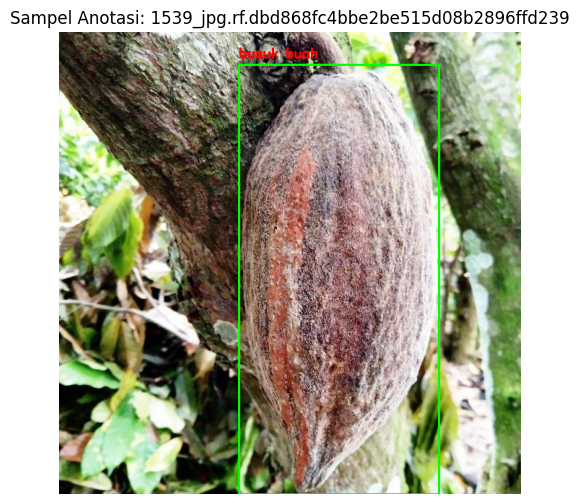

In [ ]:
import cv2
import matplotlib.pyplot as plt

img_dir = f'{DATASET_LOCAL}/train/images'
lbl_dir = f'{DATASET_LOCAL}/train/labels'

all_images = glob.glob(f'{img_dir}/*.*')
if all_images:
    img_path = random.choice(all_images)
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    base = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = f'{lbl_dir}/{base}.txt'

    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f:
                p = line.strip().split()
                if len(p) == 5:
                    cls_id = int(p[0])
                    xc, yc, bw, bh = map(float, p[1:])
                    x1, y1 = int((xc - bw/2) * w), int((yc - bh/2) * h)
                    x2, y2 = int((xc + bw/2) * w), int((yc + bh/2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    cv2.putText(img, names[cls_id], (x1, max(y1 - 10, 10)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Sampel Anotasi: {base}")
    plt.axis('off')
    plt.show()
else:
    print("Tidak ada gambar di direktori train.")

In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

results = model.train(
    data=YAML_LOCAL,        # baca dari disk lokal
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    optimizer='auto',
    seed=42,
    cos_lr=True,
    project=RUNS_DRIVE,     # hasil ditulis ke Drive
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    save=True,
    save_period=10,
    workers=2,
)

best_model = f'{RUNS_DRIVE}/{RUN_NAME}/weights/best.pt'
last_model = f'{RUNS_DRIVE}/{RUN_NAME}/weights/last.pt'
print("Best model ada:", os.path.exists(best_model))
print("Last model ada:", os.path.exists(last_model))
print("Lokasi best   :", best_model)

# Simpan YAML yang dipakai agar eksperimen bisa direproduksi
shutil.copy(YAML_LOCAL, f'{RUNS_DRIVE}/{RUN_NAME}/data_used.yaml')

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=kakao_yolov8n_50ep, nbs=64, nms=None, opset=None, optimize=False, o

'/content/drive/MyDrive/HASIL_YOLOV8_KAKAO_V2_50EPOCH/kakao_yolov8n_50ep/data_used.yaml'

In [ ]:
from ultralytics import YOLO

best_model = f'{RUNS_DRIVE}/{RUN_NAME}/weights/best.pt'
model = YOLO(best_model)

metrics = model.val(
    data=YAML_LOCAL,
    split='test',
    project=RUNS_DRIVE,
    name=f'{RUN_NAME}_test',
    exist_ok=True,
    plots=True,
)

print(f"Precision : {metrics.box.mp:.3f}")
print(f"Recall    : {metrics.box.mr:.3f}")
print(f"mAP50     : {metrics.box.map50:.3f}")
print(f"mAP50-95  : {metrics.box.map:.3f}")
for i, n in enumerate(names):
    print(f"{n:<16} mAP50={metrics.box.ap50[i]:.3f}  mAP50-95={metrics.box.all_ap[i].mean():.3f}")

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1272.8±285.4 MB/s, size: 72.8 KB)
val: Scanning /content/Dataset_Kakao_Version_2/test/labels... 167 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 167/167 873.7it/s 0.2s
val: New cache created: /content/Dataset_Kakao_Version_2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.0it/s 5.5s
                   all        167        170      0.971      0.955      0.989      0.953
                 Sehat         48         48          1      0.939      0.991      0.974
            busuk buah         36         37      0.949      0.999      0.993       0.93
        kepik pengisap         34         34      0.949      0.941      0.982      0.965
        penggerek buah         49         51      0.9

results.png


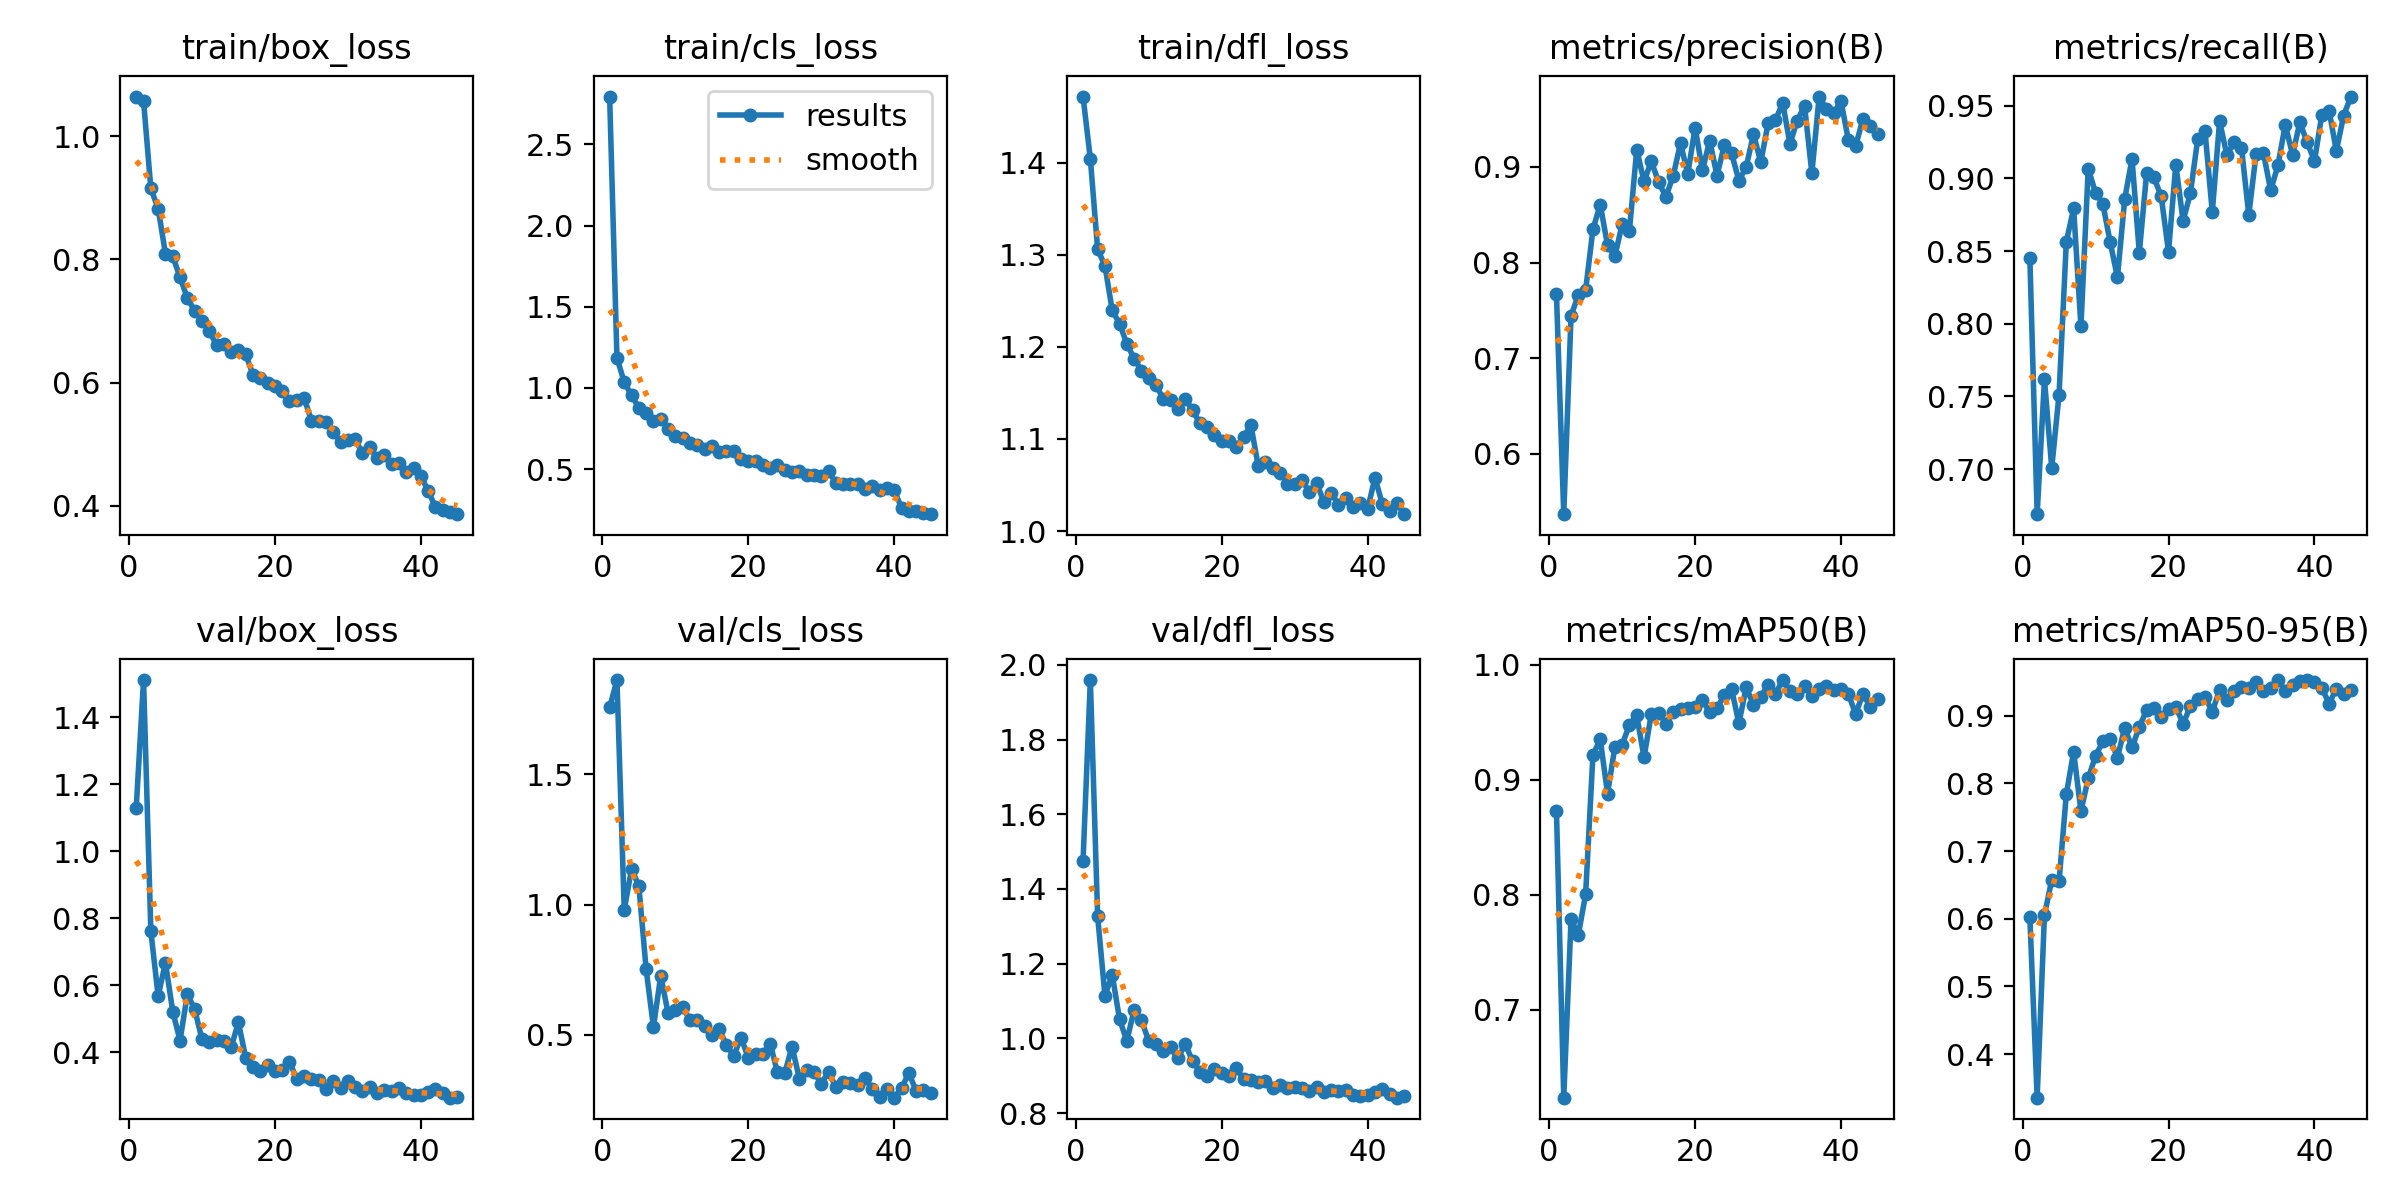

confusion_matrix_normalized.png


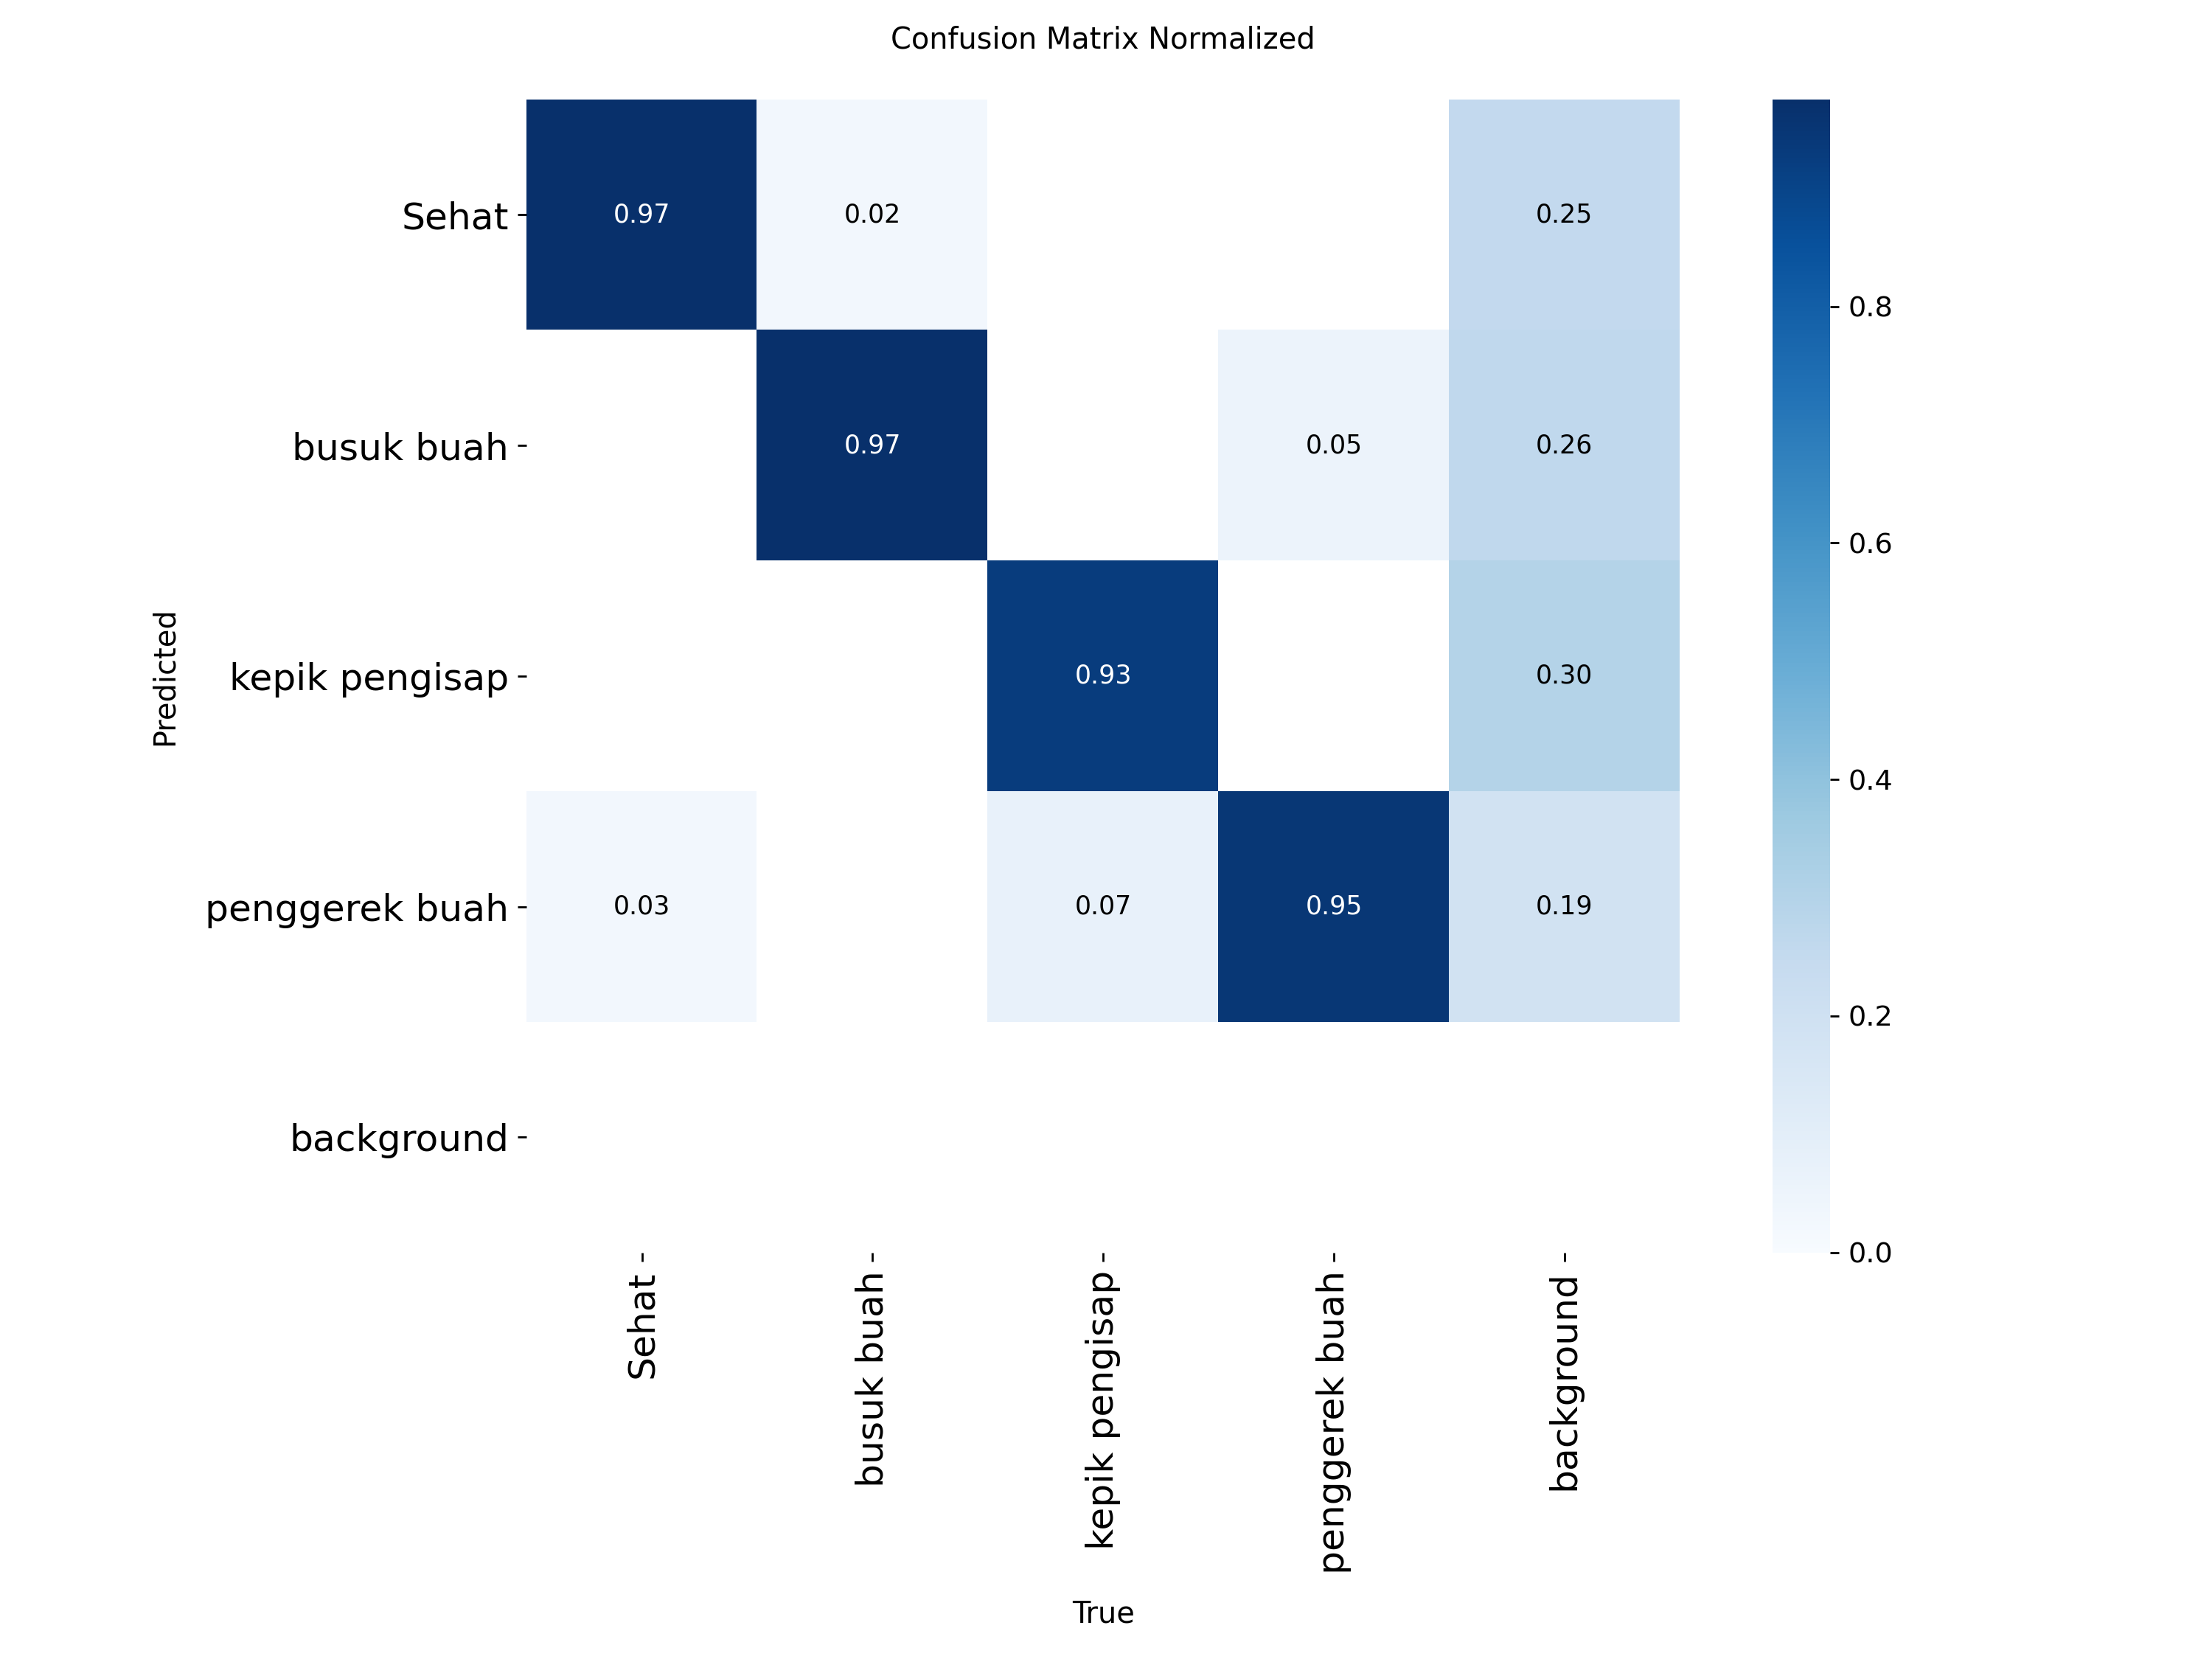

BoxPR_curve.png


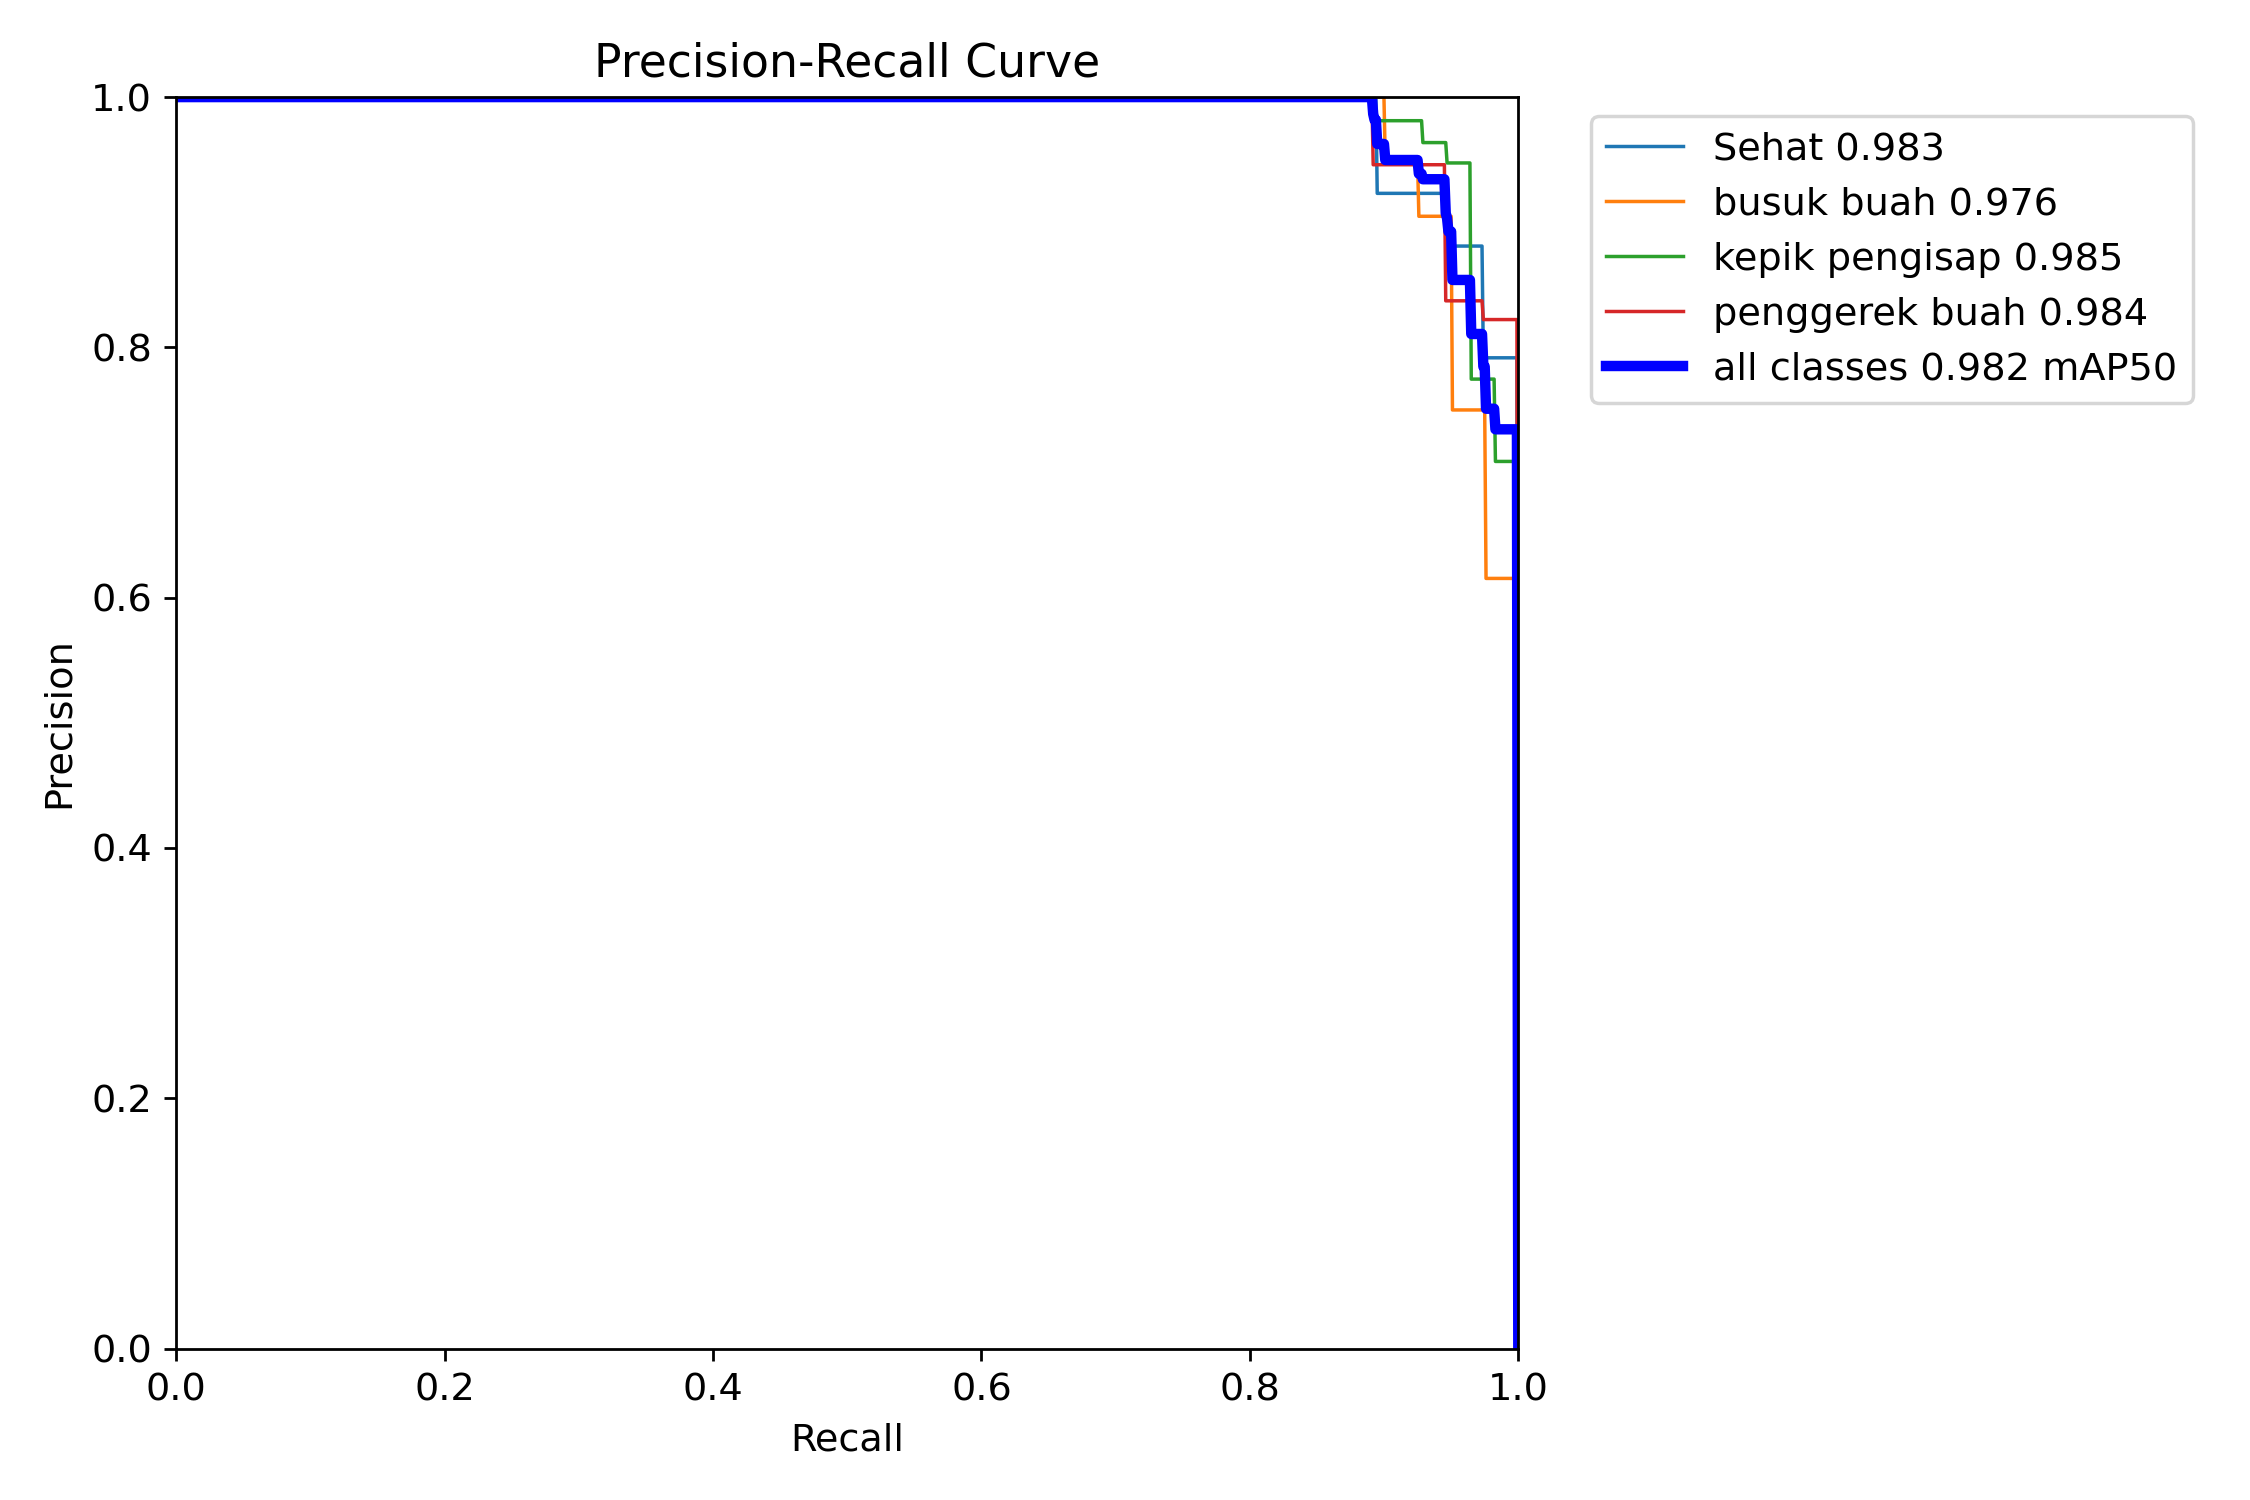

In [ ]:
from IPython.display import Image, display

d = f'{RUNS_DRIVE}/{RUN_NAME}'
for f in ['results.png', 'confusion_matrix_normalized.png', 'BoxPR_curve.png']:
    p = f'{d}/{f}'
    if os.path.exists(p):
        print(f)
        display(Image(p, width=700))

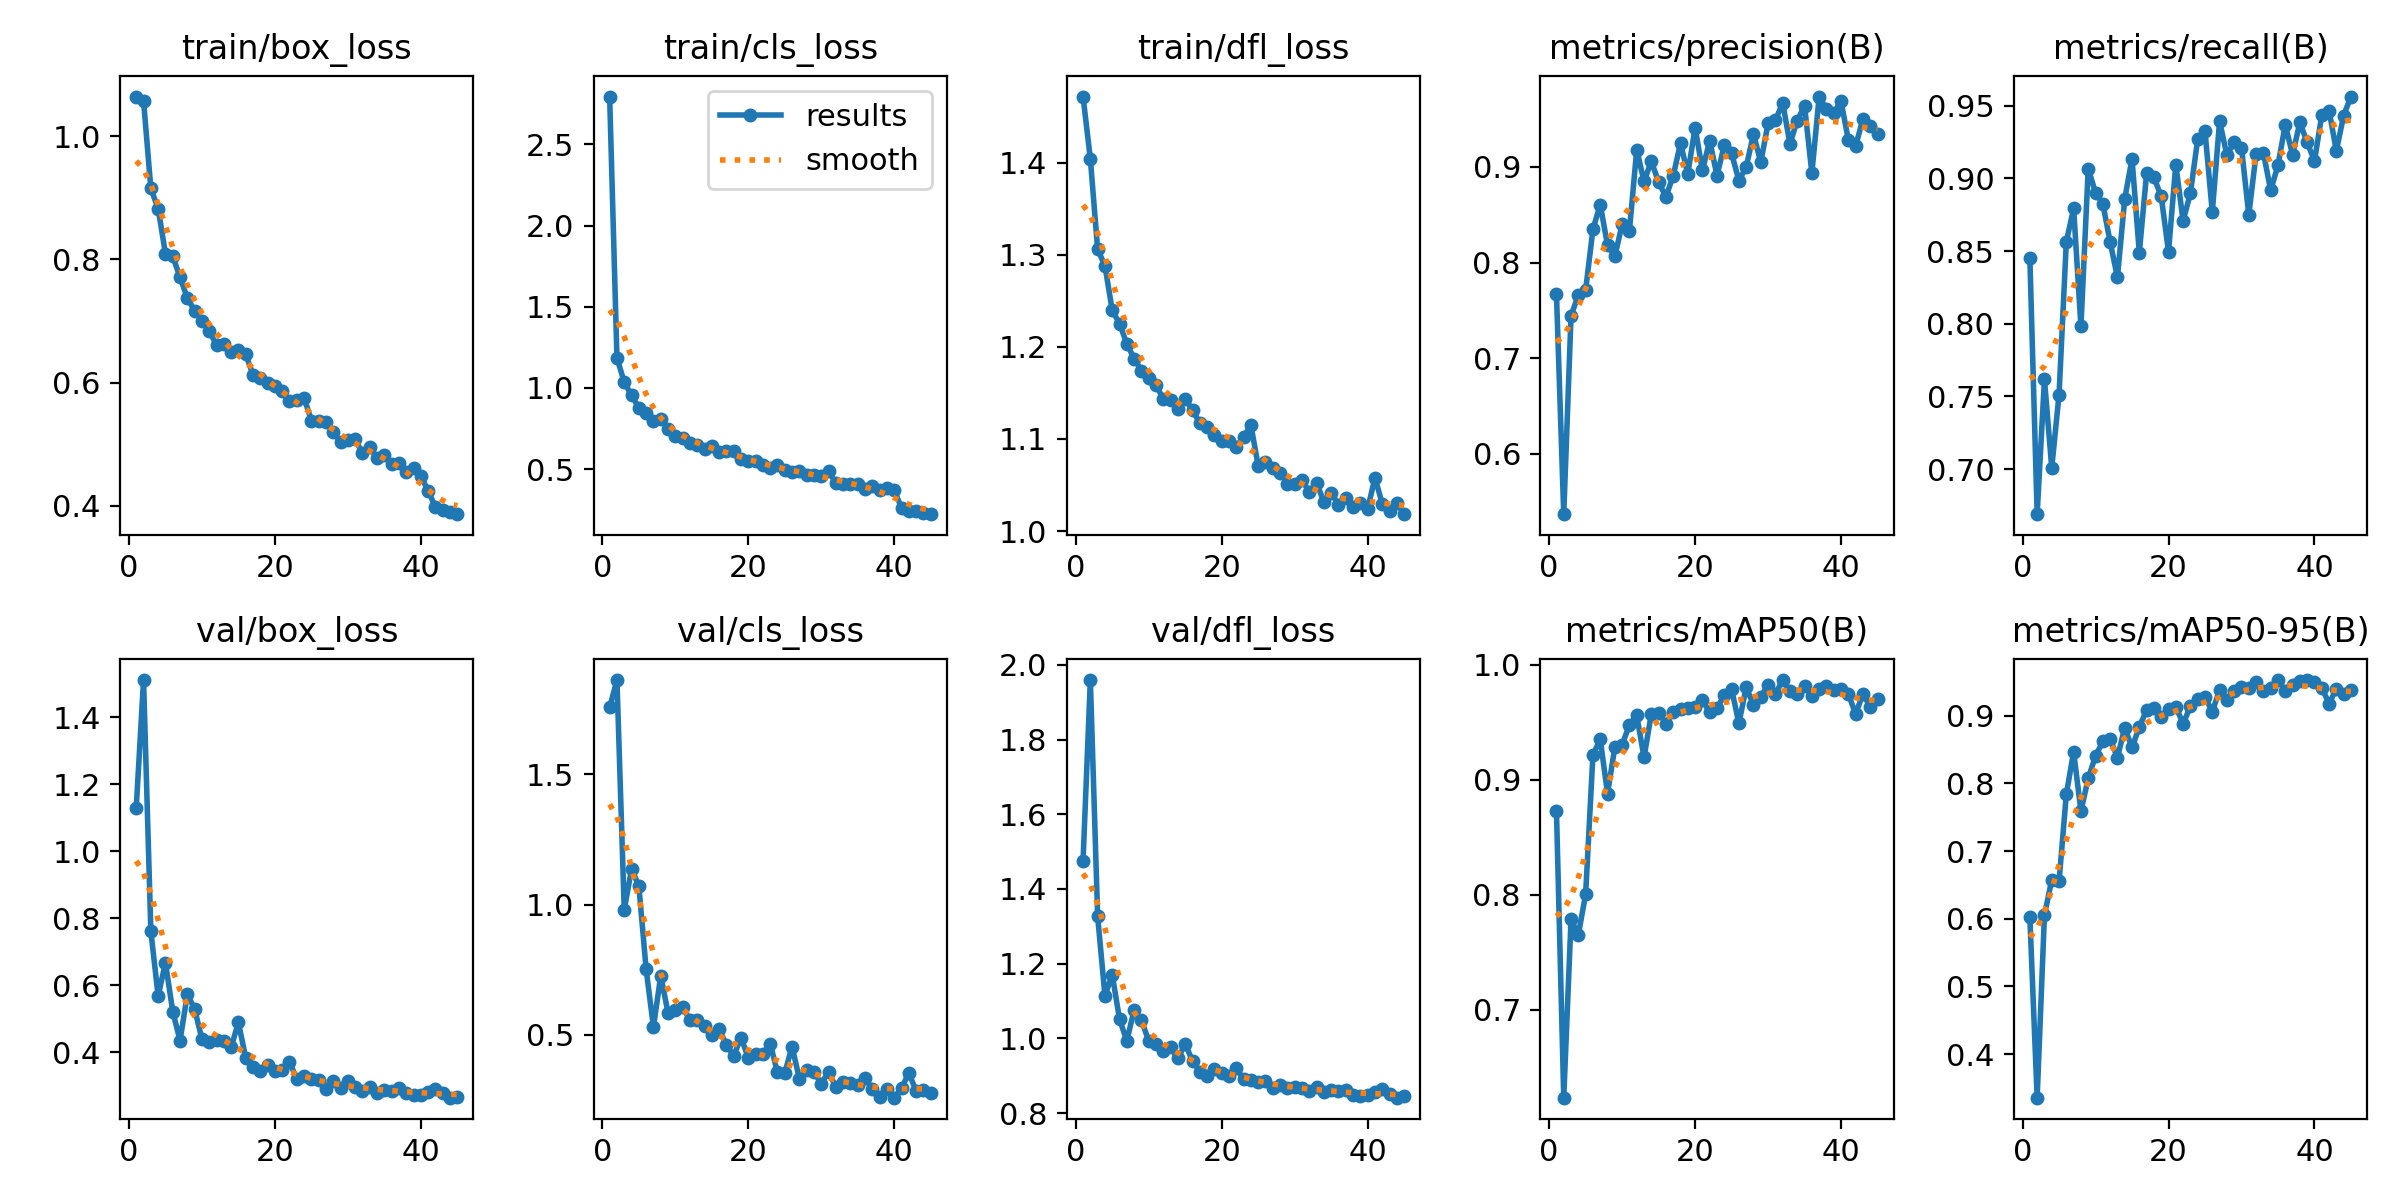


=== confusion_matrix.png ===


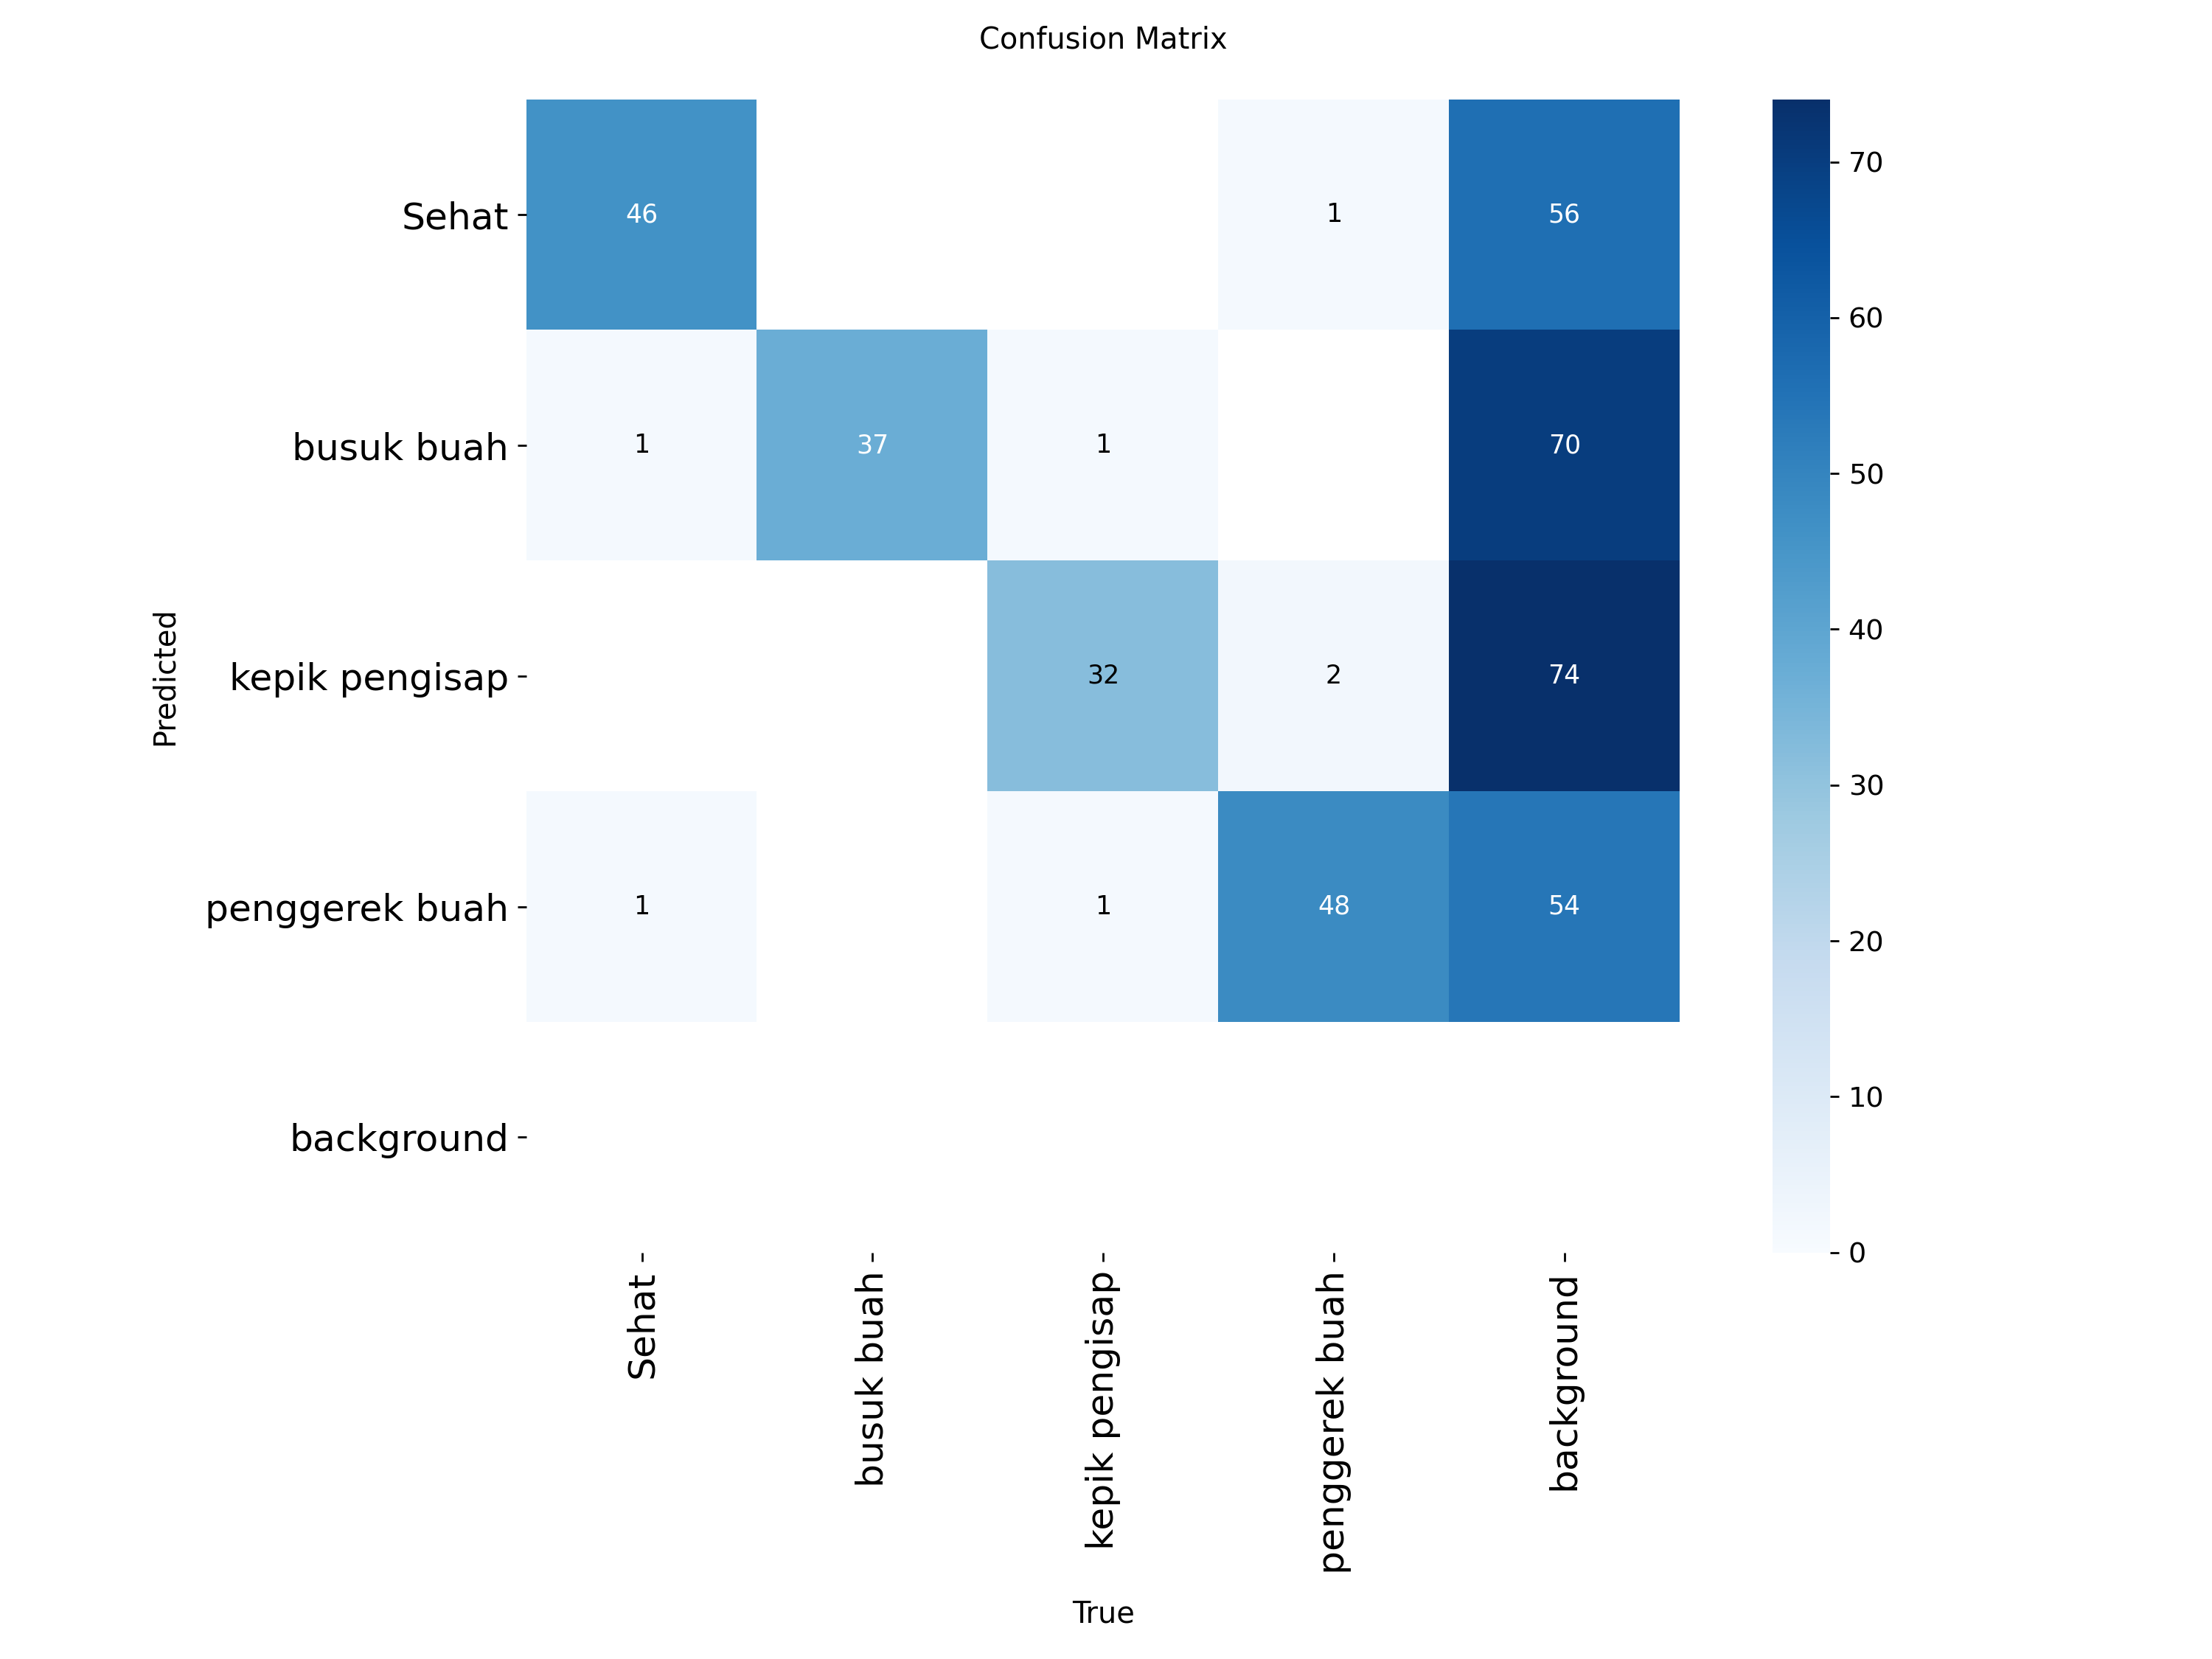


=== confusion_matrix_normalized.png ===


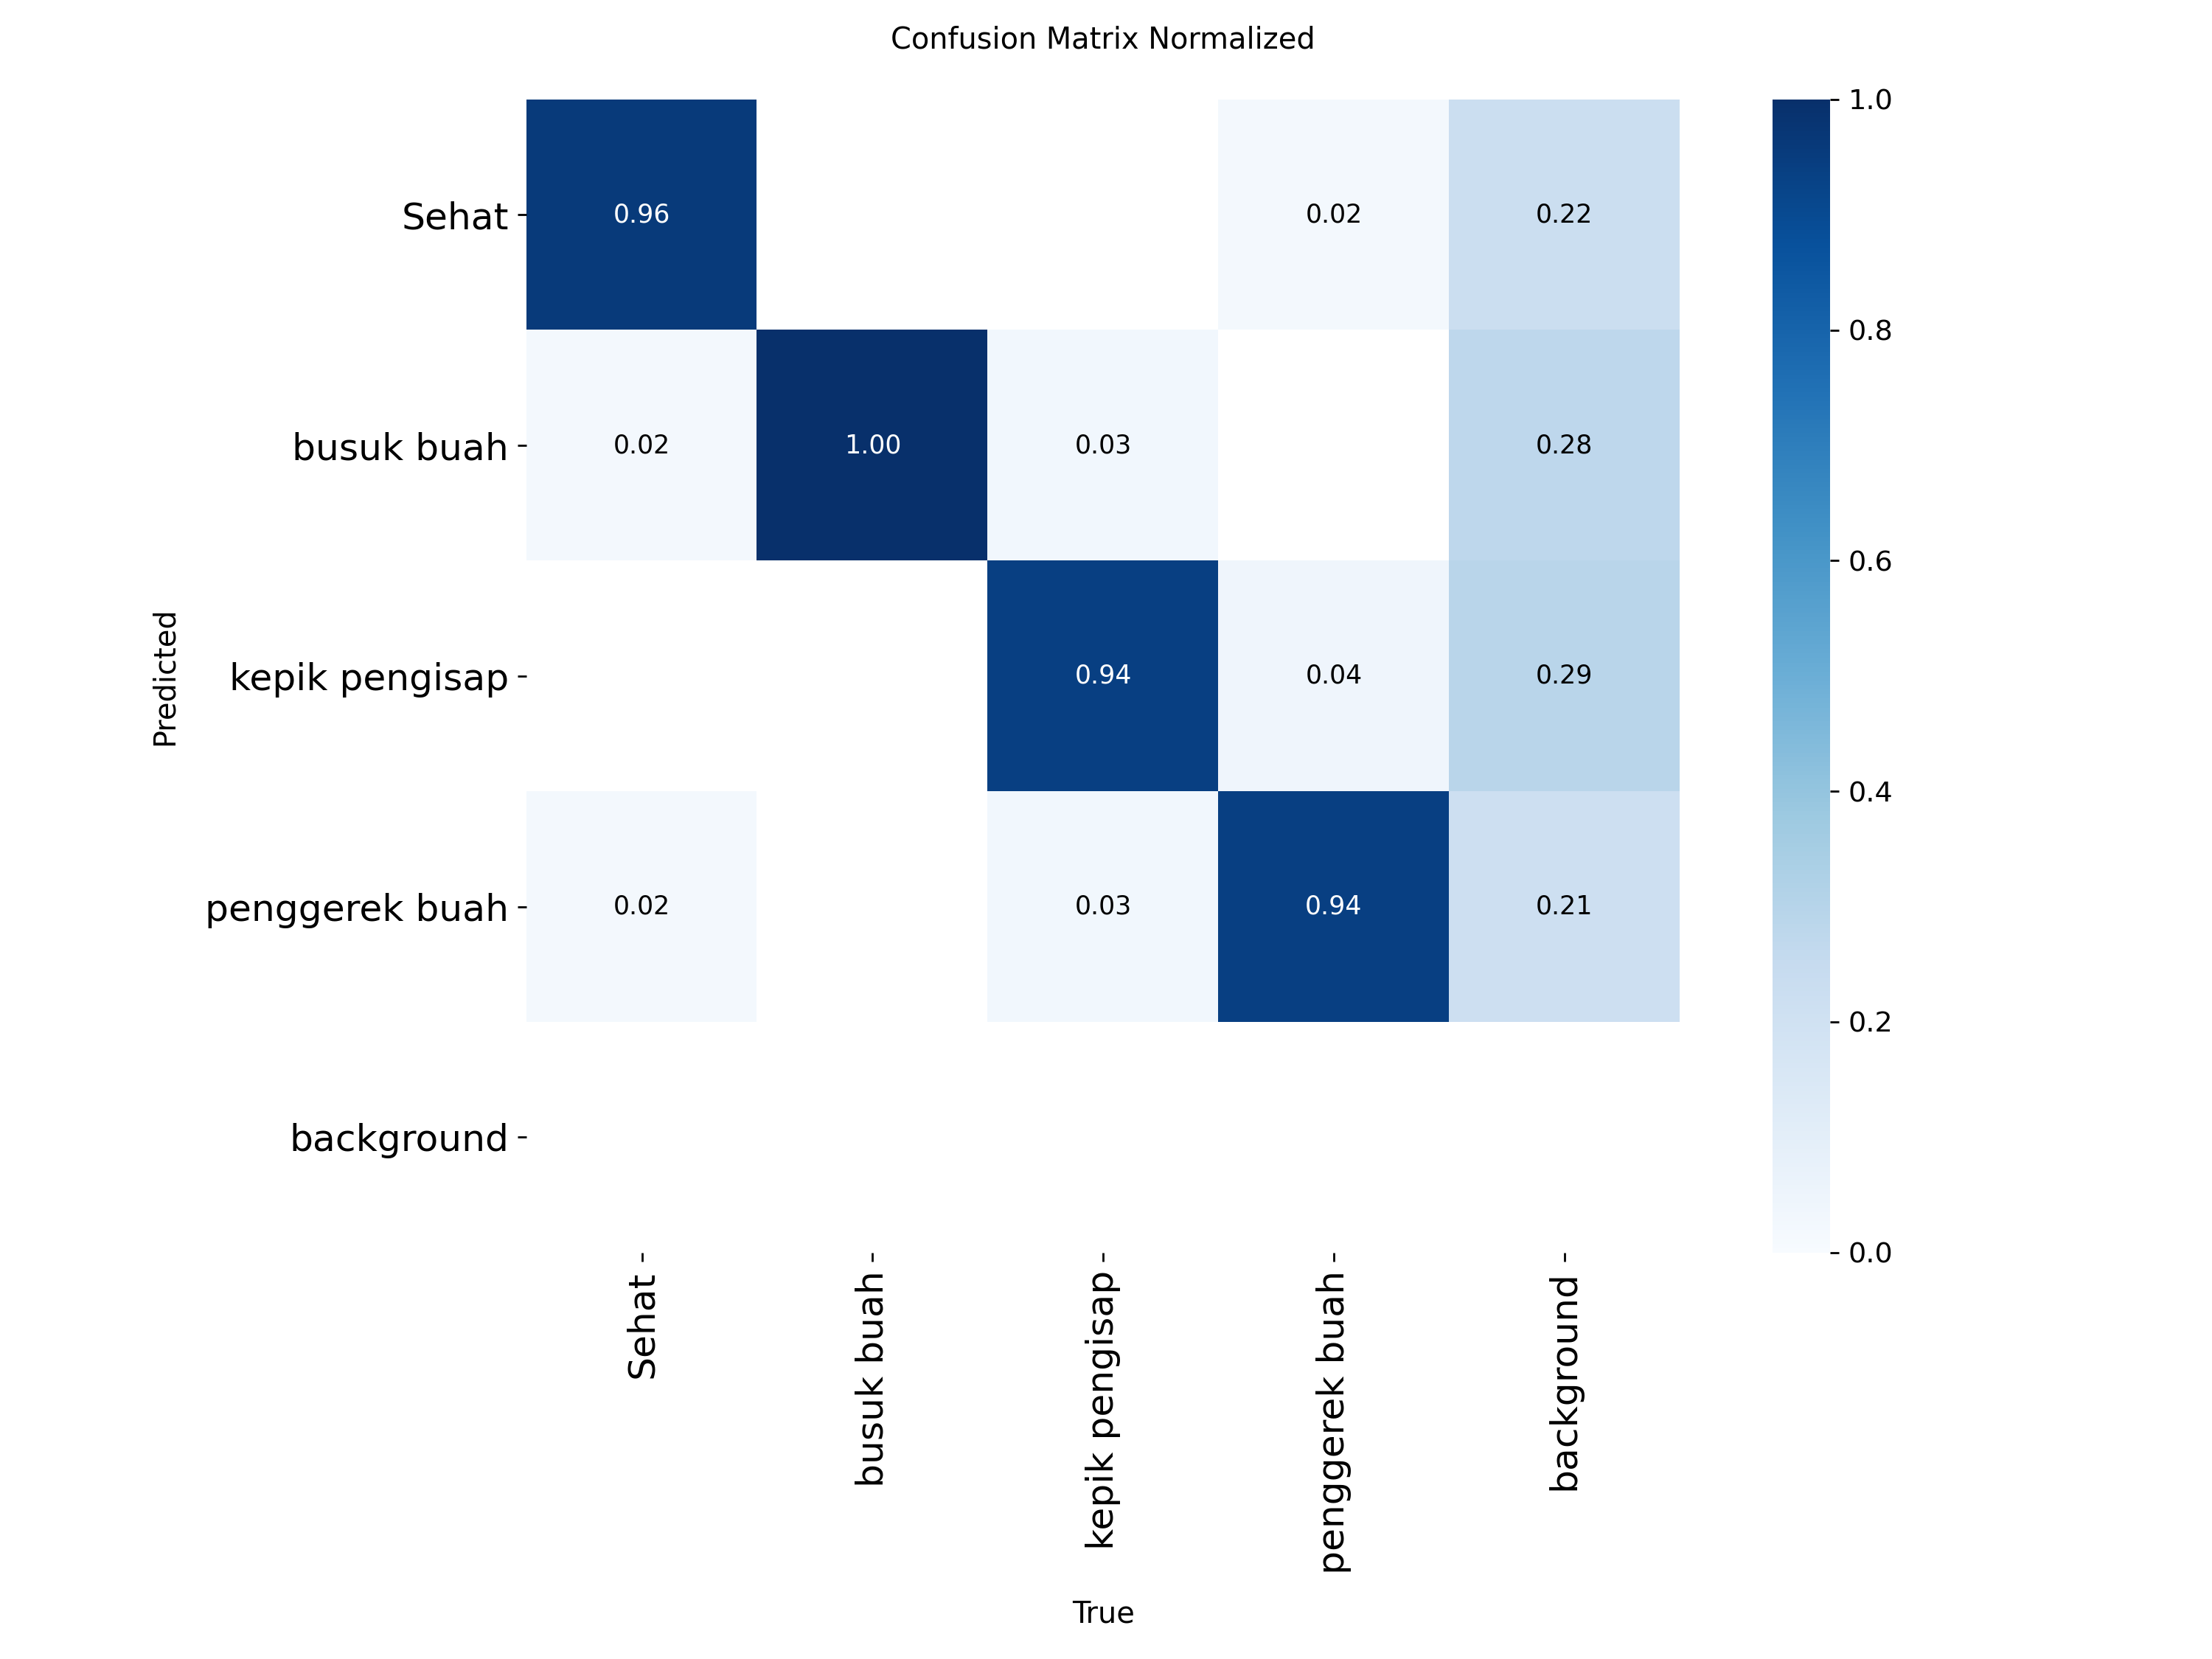


=== BoxPR_curve.png ===


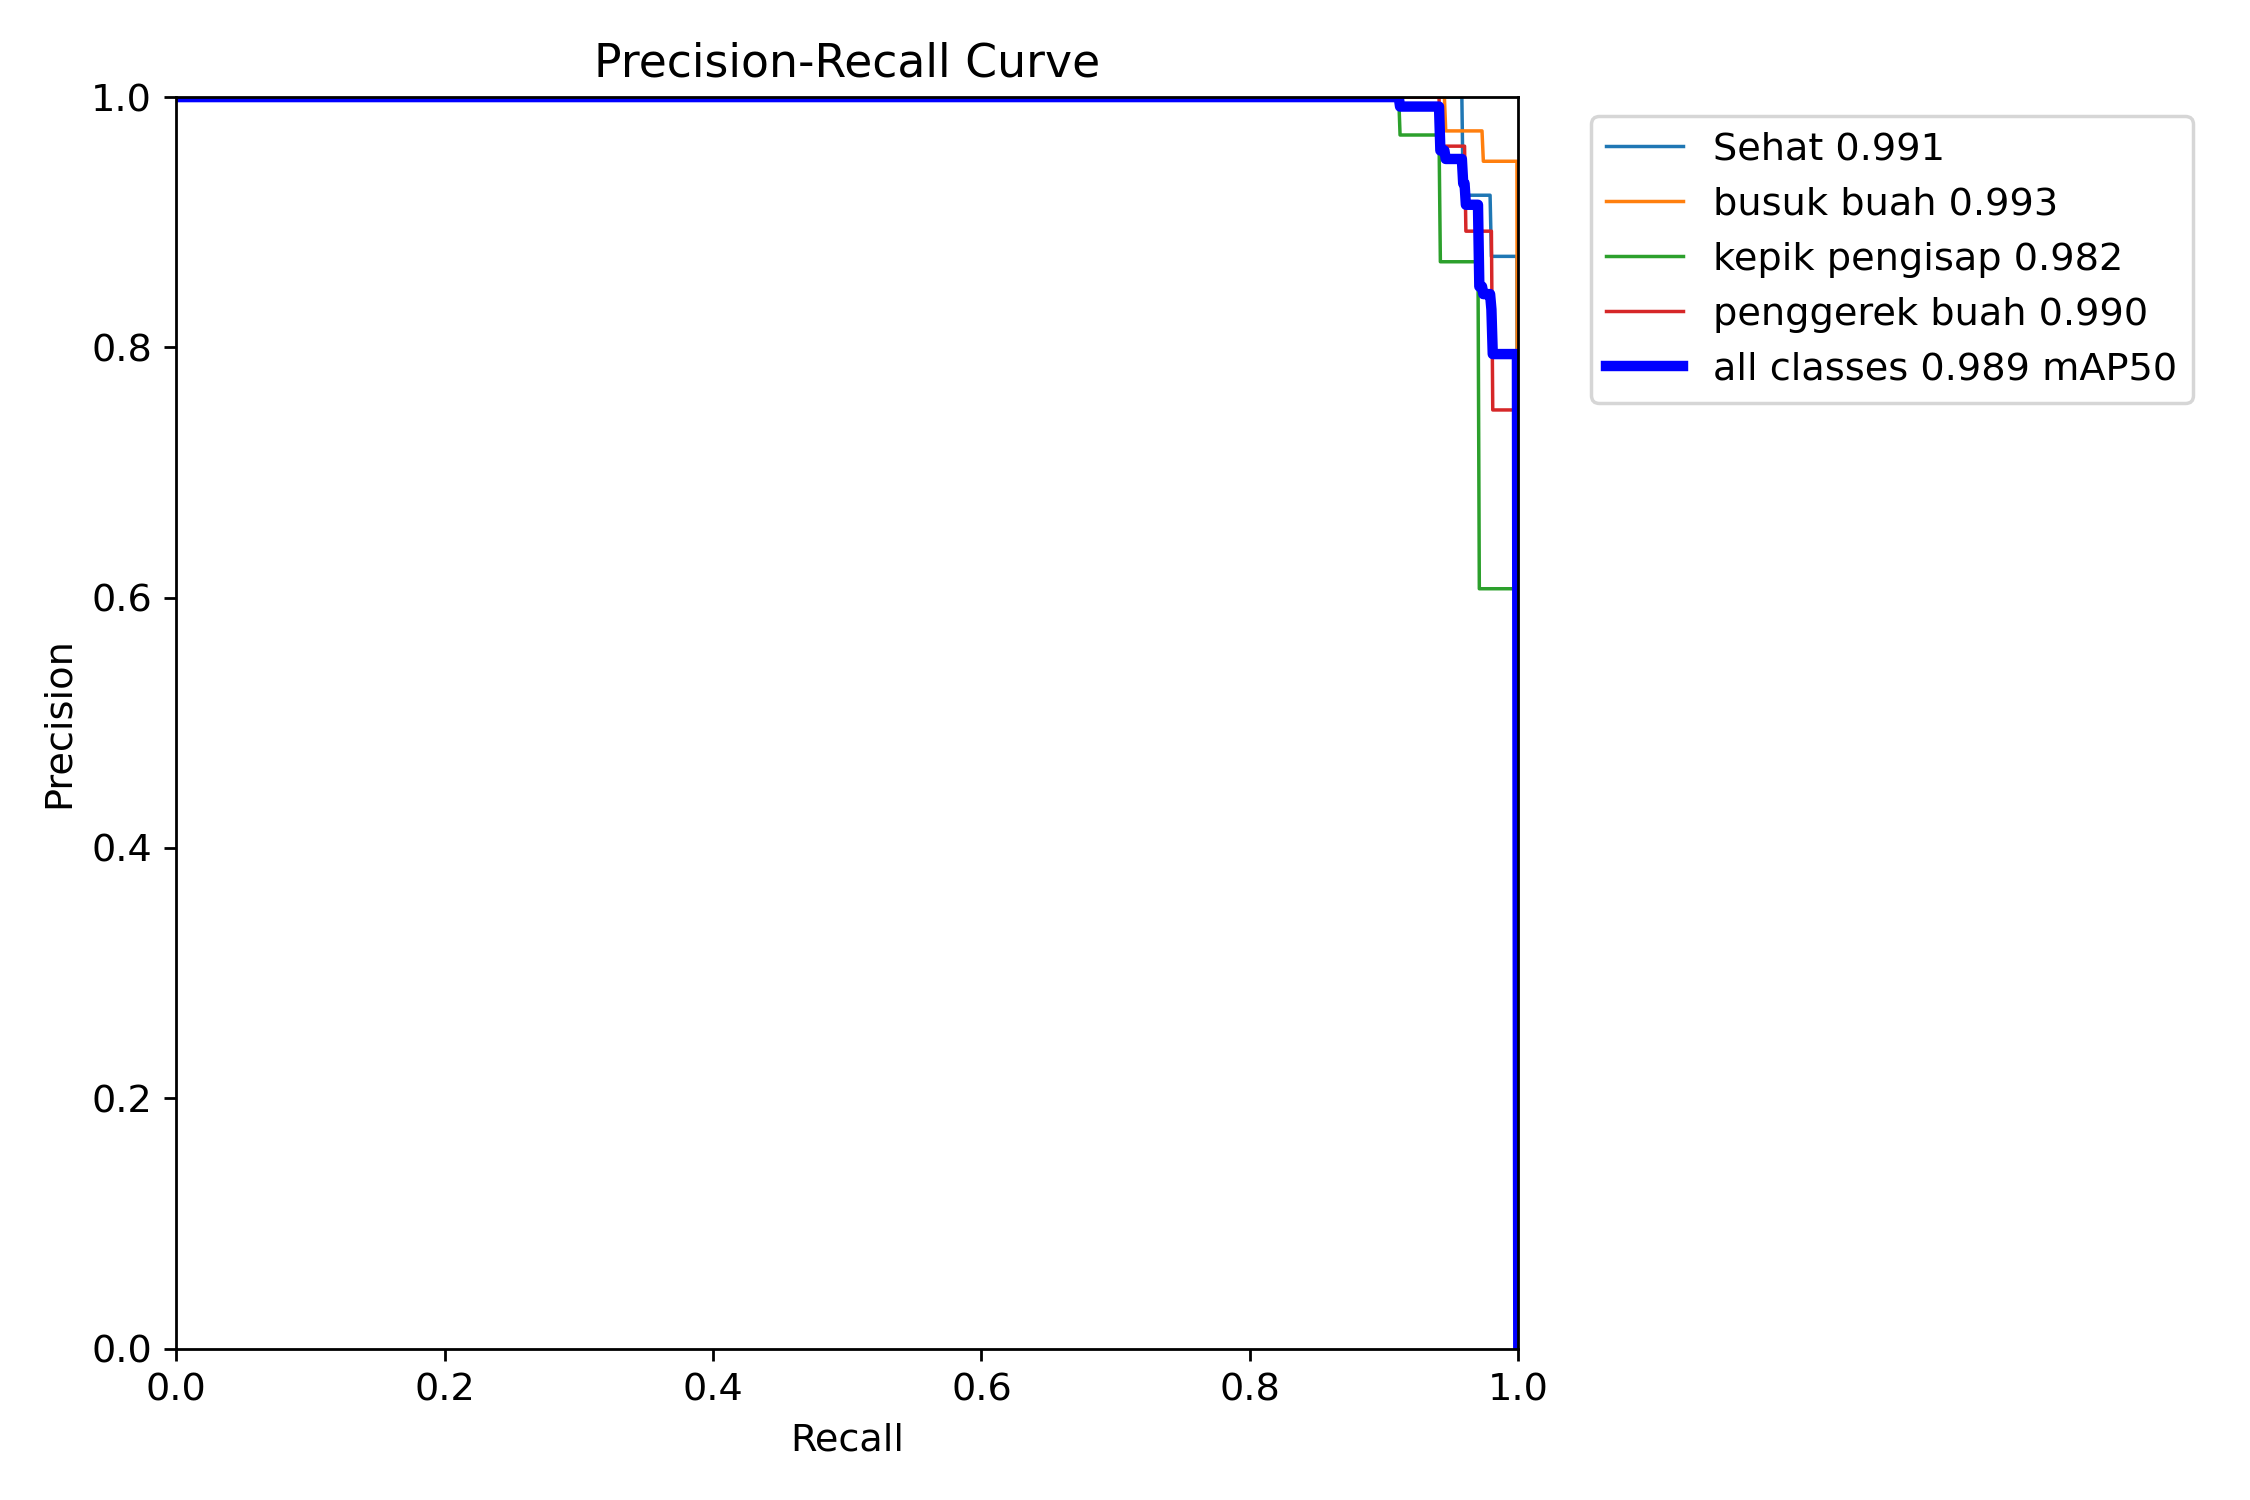


=== BoxF1_curve.png ===


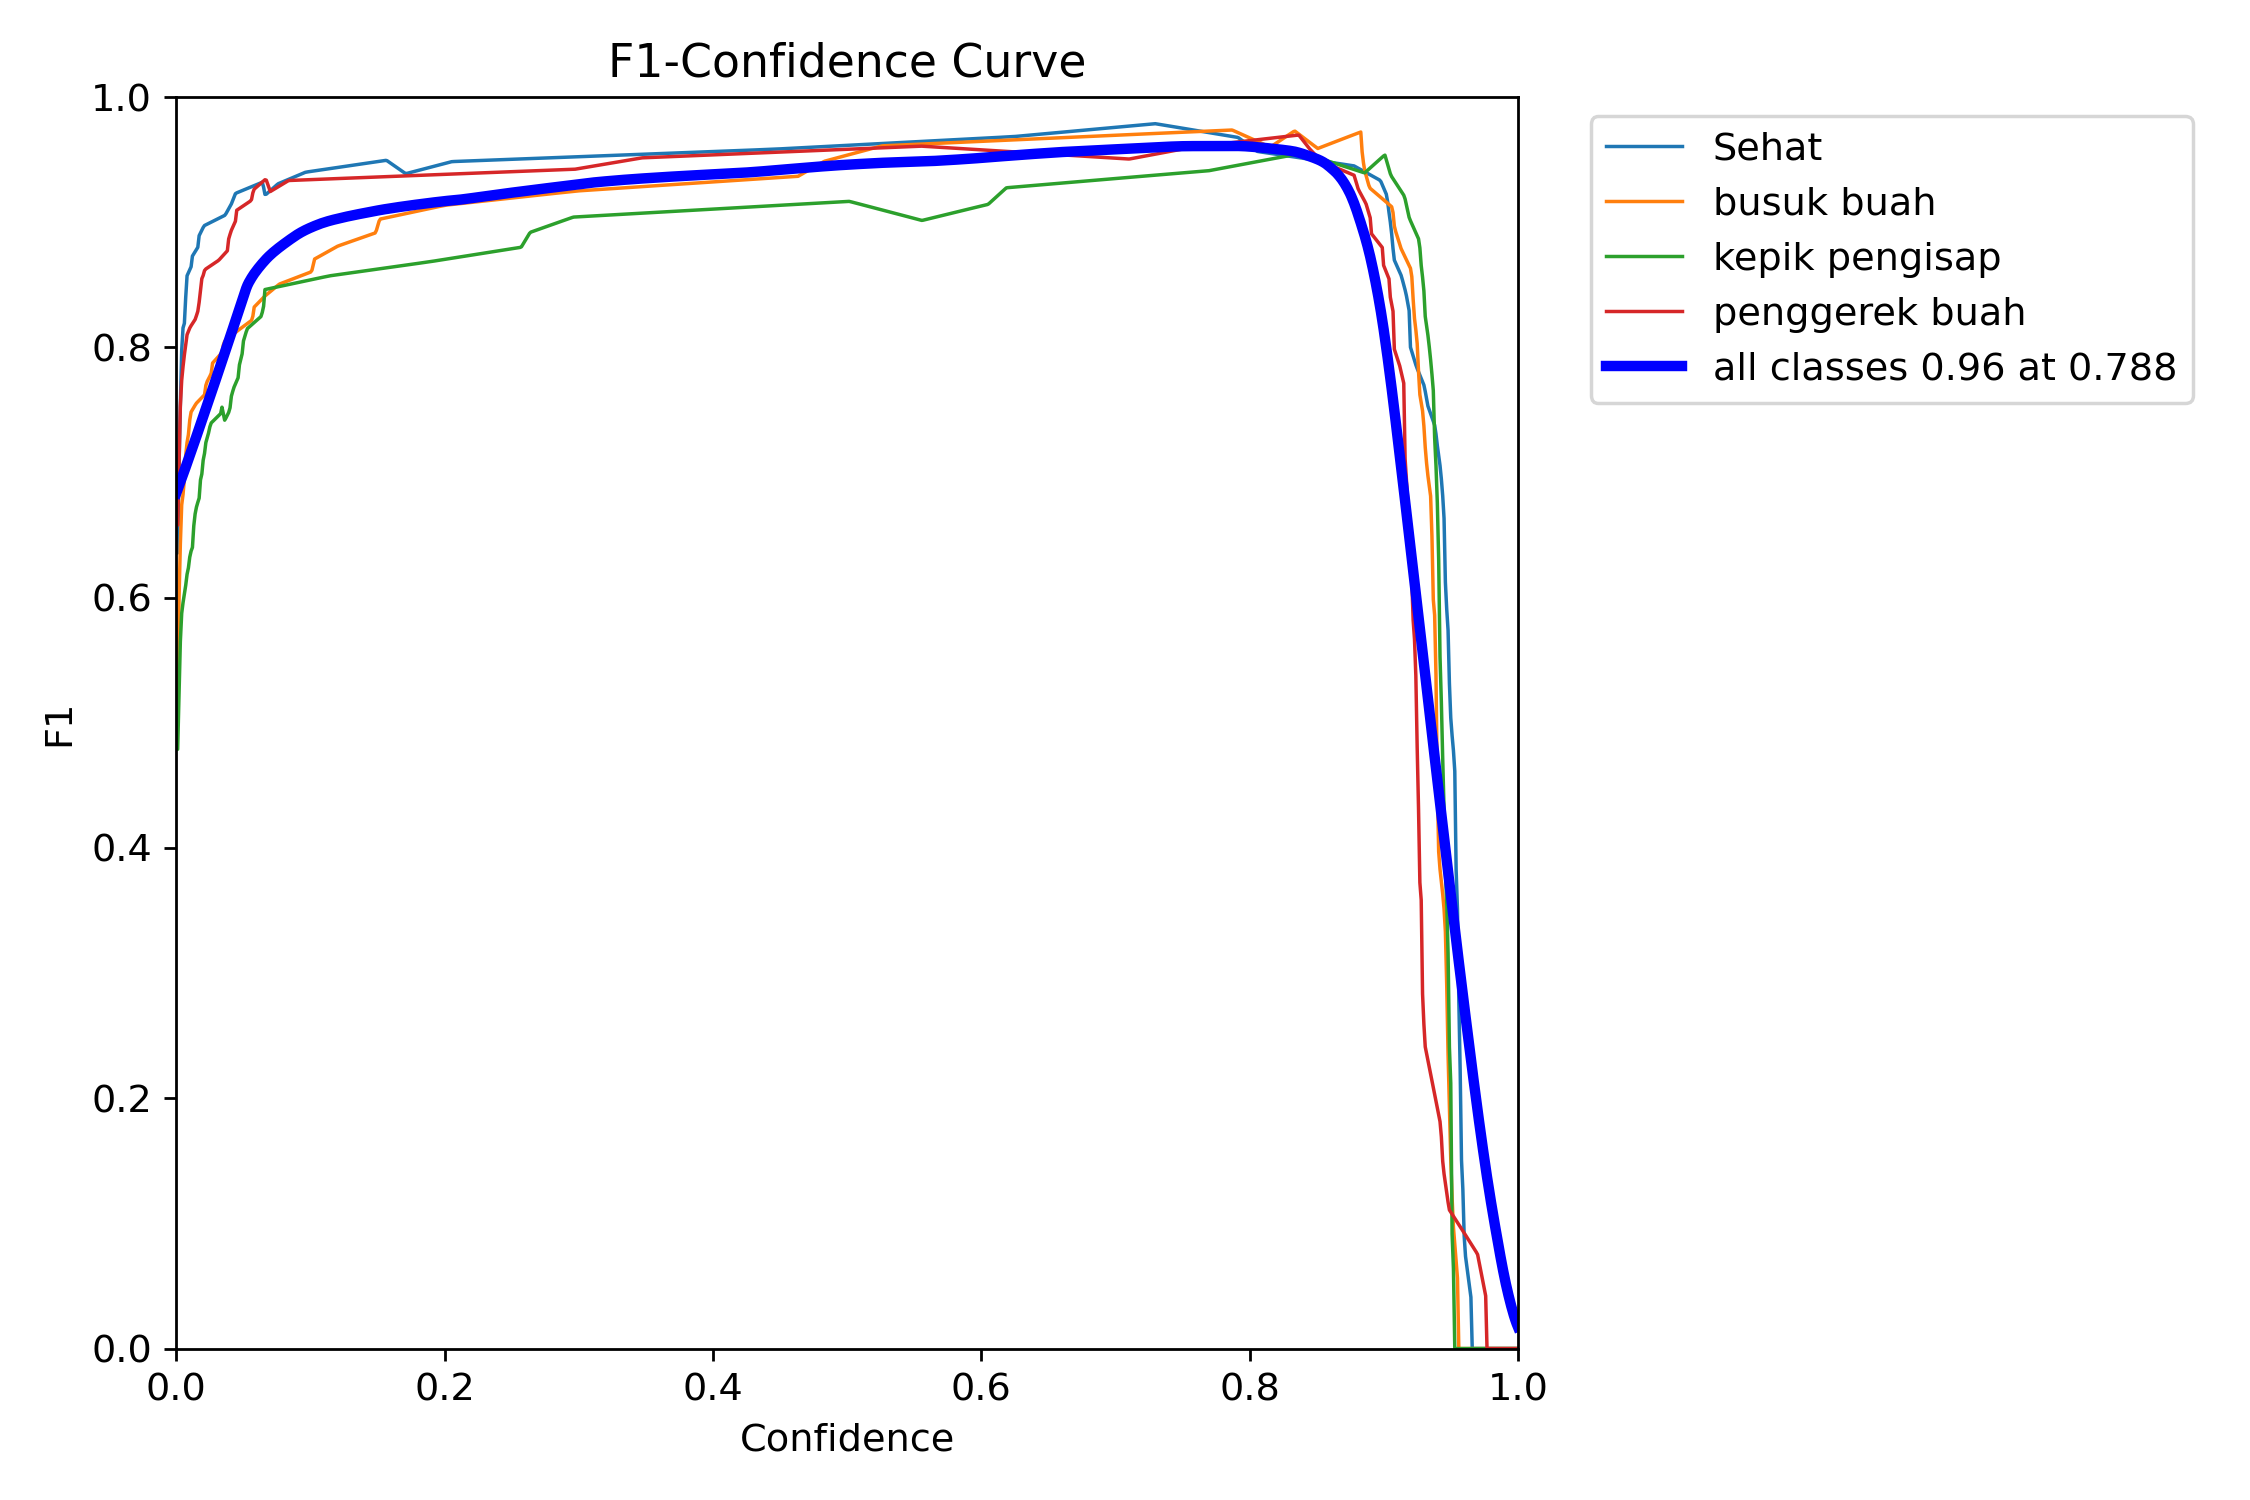

In [ ]:
from IPython.display import Image, display
import os

run_dir  = f'{RUNS_DRIVE}/{RUN_NAME}'
eval_dir = f'{RUNS_DRIVE}/{RUN_NAME}_test'

# Grafik training
display(Image(filename=f'{run_dir}/results.png', width=900))

# Grafik evaluasi test
for f in ['confusion_matrix.png', 'confusion_matrix_normalized.png',
          'BoxPR_curve.png', 'BoxF1_curve.png']:
    path = os.path.join(eval_dir, f)
    if os.path.exists(path):
        print(f"\n=== {f} ===")
        display(Image(filename=path, width=700))
    else:
        print(f"{f} tidak ditemukan di {eval_dir}")

In [ ]:
from ultralytics import YOLO
import os

best_model = f'{RUNS_DRIVE}/{RUN_NAME}/weights/best.pt'
assert os.path.exists(best_model), "best.pt tidak ditemukan, cek path RUNS_DRIVE dan RUN_NAME"
model = YOLO(best_model)
names = model.names   # nama kelas diambil dari model
print("Model siap. Kelas:", names)

Model siap. Kelas: {0: 'Sehat', 1: 'busuk buah', 2: 'kepik pengisap', 3: 'penggerek buah'}


In [ ]:
from google.colab import files

uploaded = files.upload()          # pilih satu atau beberapa gambar
img_paths = list(uploaded.keys())
print("Gambar diunggah:", img_paths)

Saving IMG_20261003_114737_733.jpg to IMG_20261003_114737_733 (1).jpg
Gambar diunggah: ['IMG_20261003_114737_733 (1).jpg']



=== IMG_20261003_114737_733 (1).jpg ===
- penggerek buah: 0.13


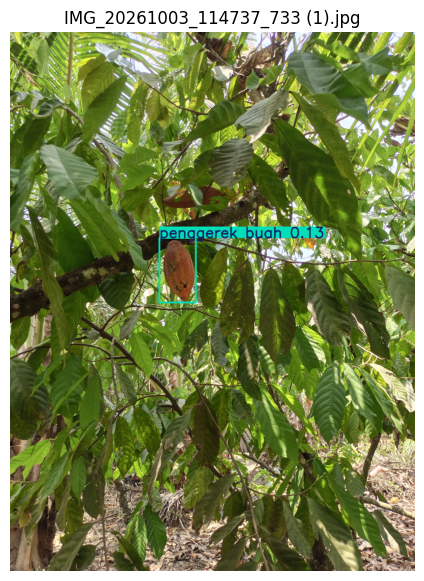

In [ ]:
import cv2
import matplotlib.pyplot as plt

CONF = 0.1   # ambang kepercayaan; turunkan (0.1) jika tidak ada yang terdeteksi

for p in img_paths:
    r = model.predict(p, conf=CONF, imgsz=640, verbose=False)[0]

    # Ringkasan teks
    print(f"\n=== {p} ===")
    if len(r.boxes) == 0:
        print("Tidak ada objek terdeteksi.")
    for b in r.boxes:
        print(f"- {names[int(b.cls)]}: {float(b.conf):.2f}")

    # Gambar dengan bounding box
    plt.figure(figsize=(7, 7))
    plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    plt.title(p)
    plt.axis('off')
    plt.show()

In [ ]:
import os, shutil, glob, yaml, random, json
from collections import Counter

ROOT = '/content/drive/MyDrive/TUGAS_AKHIR_KAKAO'

DATASET_DRIVE = f'{ROOT}/dataset'
TRAIN_DIR     = f'{ROOT}/training'
EVAL_DIR      = f'{ROOT}/evaluasi_test'
PRED_DIR      = f'{ROOT}/prediksi'
LAPORAN       = f'{ROOT}/laporan'
RUN_NAME      = 'kakao_yolov8n_50ep'

# Salinan kerja lokal (cepat, sementara)
DATASET_LOCAL = '/content/Dataset_Kakao_Version_2'
YAML_LOCAL    = '/content/data_local.yaml'

for d in [DATASET_DRIVE, TRAIN_DIR, EVAL_DIR, PRED_DIR, LAPORAN]:
    os.makedirs(d, exist_ok=True)

print("Folder induk:", ROOT)
print(sorted(os.listdir(ROOT)))

Folder induk: /content/drive/MyDrive/TUGAS_AKHIR_KAKAO
['dataset', 'evaluasi_test', 'laporan', 'prediksi', 'training']
